# Part 1: current independent experiments

AML MIDTERM — PART 1 — CURRENT RESULTS

Best measured validation sample-wise F1: 0.91239316
Validation macro F1: 0.81044357
Earlier validation target: strictly above 0.92735. Target met: False.
Latest reported Kaggle leader: 0.93xx, exact score not provided. Local validation above 0.93: False.
This modestly exceeds the user's reported 0.9103 validation result; it does not establish a statistically reliable improvement.
Primary common grouped five-fold CV F1: 0.91047417; repeat standard deviation: 0.00737.
Same saved folds and seeds [20261126, 20261127, 20261128] for every candidate. See notebook 10 and experiments/benchmark_v1/comparison.csv.
Supplementary pooled train-plus-validation CV F1: 0.89229314; repeat standard deviation: 0.00468. This evaluates fresh fold fits of the same recipe on 235 pooled labels, not the exact saved model. See notebook 11.
Kaggle score: not measured. Validation and CV are not leaderboard scores.



In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'experiments/current-summary.json').read_text())
summary

{'updated_at': '2026-11-06T01:41:21.206522+00:00',
 'logged_cv_runs': 2293,
 'successful_cv_runs': 2244,
 'failed_attempts': 49,
 'distinct_configs': 1840,
 'validation_candidate_evaluations': 89,
 'validation_batches': 31,
 'best_validation_f1': 0.9123931623931625,
 'validation_macro_f1': 0.81044356609574,
 'descriptive_group_bootstrap_95': [0.8568376068376068, 0.9568627450980391],
 'validation_embedding_groups': 72,
 'loo_current_selected': 0.9286624203821657,
 'target': 0.92735,
 'target_met': False,
 'kaggle_score': None,
 'limitation': 'Repeated CV and validation selection cause optimism; bootstrap interval is descriptive and does not adjust for selection. Equivalent model variants and verification comparisons can recur in the validation ledger.',
 'additional_fixed_policy_cv': {'seeds': [20261111, 20261112, 20261113],
  'mean_sample_f1': 0.9037508846426042,
  'split_std': 0.003608647921863258,
  'interpretation': 'New grouped split seeds applied to the previously selected fixed m

## Selected method and validation discipline

A fixed per-reason combination uses the previous semi-supervised SVM for Safety, Funding and Efficacy, and classical tri-training for Recruitment and Other. This combination was selected from 32 masks using training-fold predictions and the frozen robust weighting criterion before validation evaluation. Empty combined predictions fall back to the base SVM's decoded labels.
Both components fit StandardScaler to gold and original masked training embeddings, retaining all 150 coordinates. No validation/test features enter the selected inductive fitters.
Base component: KMeans with 10 clusters, 10 initializations and seed 42, then five balanced RBF SVMs with C=1 and gamma=0.001. At each pseudo-label weight 0.003, 0.01 and 0.03, perform three label/refit iterations. Original gold labels remain fixed. If a cluster has at least two gold rows and at least 80% agreement for a binary reason, conflicting pseudo-labels receive one tenth the normal weight. Transform margins with sigmoid(2*margin), threshold at 0.55, and use the largest score if all labels would be empty.
Tri-training component: ordinary bootstrap samples initialize an RBF SVM (C=1, gamma=0.001), logistic regression (C=0.3), and ridge classifier (alpha=10). Peer agreement and the classical error/size conditions govern pseudo-label updates, with unit pseudo-label weight and no cluster gate in this component. Majority voting at threshold 0.5 decodes predictions; smoothed vote scores break ties for empty-label fallback. At most eight update rounds are used.
All 157 gold and 1,014 originally masked training rows are available for final inference. Validation remains excluded. Final hybrid scores are binary decisions; component margin/vote scores are not calibrated probabilities.
Earlier screens tested auxiliary criteria, disease, drug, target, action, pathway, structure and date features. They did not improve the earlier incumbent on validation; drug-target additions tied it. The new hybrid uses embeddings only. Exhaustive feature-subset testing of this new hybrid has not been performed.

EVIDENCE AND LIMITATIONS
89 recorded standalone validation candidate evaluations across 31 batches, including equivalent variants. Their hyperparameters and decision rules were chosen from training-side experiments before each small validation batch. Those original fits excluded validation labels and made no per-row corrections. Repeated aggregate comparisons still create selection bias: this is no longer a pristine holdout. The separately authorized pooled CV deliberately uses original validation labels only in the training portion of each fold, with all held-out groups excluded; it does not replace the saved training-only model or reinterpret its original validation score.
Five-fold iterative multilabel splits group identical embeddings and exclude matching masked duplicates from training. Repeats use three seeds. Leave-one-group-out evaluates 150 distinct gold embedding groups. All learned transformations stay inside their permitted folds. Temporal stress tests are affected by the intentional rare-label enrichment of later gold rows.
Descriptive grouped validation bootstrap interval: 0.8568–0.9569; this does not correct selection bias.
The search is broad, not an exhaustive enumeration of every possible algorithm or feature subset. No external trial data, extra labels, ID predictors or deep learning were used. Literature was consulted only for methods. Some explicitly marked research variants used query features transductively; the selected candidate does not.


In [2]:
ledger=pd.read_csv(root/'experiments/validation-comparisons.csv')
ledger.groupby('batch',sort=False).agg(candidates=('sample_f1','size'),best_sample_f1=('sample_f1','max'),best_macro_f1=('macro_f1','max'))

,candidates,best_sample_f1,best_macro_f1
batch,,,
validation-once,3,0.850427,0.689476
final-validation,1,0.850427,0.688413
phase3-reference-validation,8,0.871795,0.753155
phase10-validation-results,2,0.910256,0.776628
phase11-validation-results,3,0.910256,0.777778
phase12-validation-results,1,0.910256,0.780000
phase13-validation-results,1,0.901709,0.721587
phase14-validation-results,3,0.888889,0.752464
phase15-validation-results,1,0.863248,0.729862


## Current validation performance

Per-reason F1 complements the competition’s sample-wise F1. The latest reported Kaggle leader is in the 0.93xx range; its exact score is unknown. Our earlier 0.92735 target and the newer leaderboard reference both concern sample-wise F1, measured on different evaluation datasets.

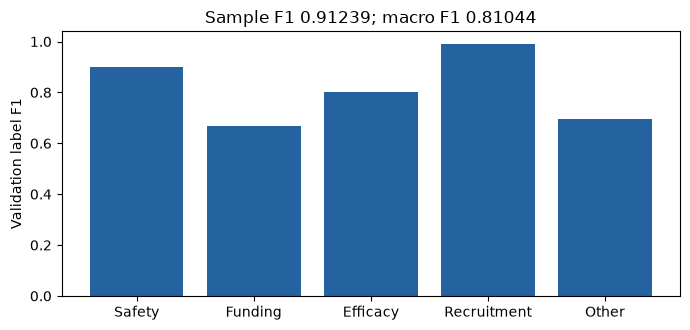

In [3]:
current=json.loads((root/'experiments/current-best.json').read_text())
m=current['candidate']['validation']
labels=['Safety','Funding','Efficacy','Recruitment','Other']
fig,ax=plt.subplots(figsize=(7,3.4))
ax.bar(labels,[m['f1_'+x] for x in labels],color='#2563a0')
ax.set(ylim=(0,1.04),ylabel='Validation label F1',title=f"Sample F1 {m['sample_f1']:.5f}; macro F1 {m['macro_f1']:.5f}")
fig.tight_layout()
(root/'figures').mkdir(exist_ok=True)
fig.savefig(root/'figures/current_validation_labels.png',dpi=180)
plt.show()

## Feature additions and model coverage

Feature settings below use training CV, including multiple weights. Their maxima are development scores, not independent estimates. Broad feature groups were added individually; selected groups were combined in earlier forward searches. No auxiliary group improved the earlier incumbent on validation. The new tri-training hybrid uses embeddings only; it has not undergone an exhaustive feature-subset search.

In [4]:
trials=[json.loads(s) for s in (root/'experiments/trials.jsonl').read_text().splitlines()]
features=[dict(features=', '.join(r['config'].get('features',[])),weight=r['config'].get('feature_weight'),cv=r['score']) for r in trials if r['tag']=='phase6_features' and r['status']=='ok']
pd.DataFrame(features).sort_values('cv',ascending=False)

,features,weight,cv
11,drug_actions,0.3,0.921444
9,drug_targets,0.3,0.921444
18,descriptors,0.1,0.921444
16,fingerprint,0.1,0.921444
14,pathway_levels,0.1,0.921444
12,drug_pathways,0.1,0.921444
10,drug_actions,0.1,0.921444
8,drug_targets,0.1,0.921444
7,icdcodes,0.3,0.920382
0,criteria,0.1,0.919321


In [5]:
ok=[r for r in trials if r['status']=='ok']
pd.DataFrame([dict(model=r['config']['model'],cv=r['score']) for r in ok]).groupby('model').agg(logged_runs=('cv','size'),best_development_cv=('cv','max')).sort_values('best_development_cv',ascending=False)

,logged_runs,best_development_cv
model,,
pseudo,110,0.940552
joint_specialist,23,0.940552
svc,231,0.940552
logistic,118,0.938429
iterative_ssl,26,0.938429
...,...,...
xgb,3,0.859873
lightgbm,1,0.856688
rf,3,0.852442


## Reproduction and historical results

Run notebook 04 to regenerate the current predictions with embedded source. All raw data hashes and original gold labels are checked. Notebooks 01/02 preserve the earlier 0.850427 validation model; their final-candidate wording is historical. The newer notebooks and current_best directory supersede that candidate.

The full experiment log retains unsuccessful trials and error records. Phase 10 initially had a non-contiguous sample-weight array error, which was corrected before valid results. The first phase 17 XGBoost run emitted an unused `lambda_` warning and used native default L2=1; the source now spells the same effective value as `reg_lambda=1`. No measured hyperparameter changed in this correction.

## Technique references

[Semi-supervised learning (scikit-learn documentation)](https://scikit-learn.org/stable/modules/semi_supervised.html) — Graph propagation/spreading and confidence-controlled pseudo-labeling; not an external source of trial records.

[Nested versus non-nested cross-validation (scikit-learn)](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html) — Separate model-selection scores from estimates of generalization.

[Clustering (scikit-learn documentation)](https://scikit-learn.org/stable/modules/clustering.html) — Compare geometric assumptions and inductive extensions for multiple cluster families.

[Zhu, Ghahramani, Lafferty (2003), Semi-Supervised Learning Using Gaussian Fields and Harmonic Functions](https://www.cs.cornell.edu/courses/cs6241/2019sp/readings/ZGL-2003-SSL.pdf) — Harmonic graph inference with known-label boundary conditions.

[Zhou et al. (2004), Learning with Local and Global Consistency](https://www.cs.cornell.edu/courses/cs6241/2020sp/readings/Zhou-2004-global-local.pdf) — Normalized graph diffusion; custom multi-output implementation.

[Waegeman et al. (2014), On the Bayes-Optimality of F-Measure Maximizers](https://jmlr.org/papers/v15/waegeman14a.html) — Decision-theoretic motivation for sample-F1 decoder. Our simple enumeration uses independent marginal probabilities, not the full GFM joint-distribution algorithm.

[Read et al. (2009), Classifier Chains for Multi-label Classification](https://ml.cms.waikato.ac.nz/publications/2009/chains.pdf) — Evaluate label-dependence models with cross-fitted chain features.

[RDKit Getting Started](https://www.rdkit.org/docs/GettingStartedInPython.html) — Morgan fingerprints and numerical descriptors computed only from supplied SMILES.

[Joachims (1999), Transductive Inference for Text Classification using Support Vector Machines](https://www.cs.cornell.edu/people/tj/publications/joachims_99c.pdf) — Motivation for low-density semi-supervised margins. Our alternating pseudo-label procedure is a heuristic, not an implementation of the exact TSVM optimization algorithm.

[Huang et al., Correcting Sample Selection Bias by Unlabeled Data](https://papers.nips.cc/paper_files/paper/2006/hash/a2186aa7c086b46ad4e8bf81e2a3a19b-Abstract.html) — Kernel mean matching weights, estimated only against original masked training features.

[On Mixup Regularization](https://www.jmlr.org/papers/v23/20-1385.html) — Motivation for synthetic interpolation; evaluated with classical logistic/SVM learners only.

[Nystroem kernel approximation, scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.kernel_approximation.Nystroem.html) — Classical finite kernel features for comparing squared hinge, logistic and squared losses.

[Cortes, Mohri, Rostamizadeh: Algorithms for Learning Kernels Based on Centered Alignment](https://www.jmlr.org/papers/v13/cortes12a.html) — Search-gap audit and classical methods; no additional trial data.

[Zhou and Li: Tri-Training](https://www.lamda.nju.edu.cn/publication/tkde05.pdf) — Search-gap audit and classical methods; no additional trial data.

[SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) — Search-gap audit and classical methods; no additional trial data.

[Sugiyama, Krauledat, Müller (2007): Covariate Shift Adaptation by Importance Weighted Cross Validation](https://www.jmlr.org/papers/v8/sugiyama07a.html) — Motivation for target-aware model selection. Estimated, clipped weights and label-dependent sampling here do not establish an unbiased target-risk guarantee.

[Breiman: Bagging Predictors](https://statistics.berkeley.edu/tech-reports/421) — Motivation for averaging fixed bootstrap runs; no best-seed selection.

[scikit-learn: StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html) — Meta-learners must learn from out-of-fold component predictions; custom implementation uses embedding-grouped inner folds.

[Dembczynski et al.: An Exact Algorithm for F-Measure Maximization](https://proceedings.neurips.cc/paper/2011/hash/71ad16ad2c4d81f348082ff6c4b20768-Abstract.html) — Exact expected sample-F1 decoding under an estimated label-pattern distribution; estimated probabilities need not be correct.

[Blum and Mitchell: Combining Labeled and Unlabeled Data with Co-Training](https://www.cs.cmu.edu/~avrim/Papers/cotrain.pdf) — Motivation for separate embedding/metadata views exchanging pseudo-labels. Our quota, agreement, weighting and cluster safeguards are adaptations; the original assumptions are not established here.

[scikit-learn: NeighborhoodComponentsAnalysis](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NeighborhoodComponentsAnalysis.html) — Gold-only per-reason linear metric learning, combined with original distances in an SVM kernel.

[scikit-learn: Probability calibration](https://scikit-learn.org/stable/modules/calibration.html) — OOF score calibration motivates reliability estimates for pseudo-label weighting. Our target distribution is shifted, so calibrated target-domain accuracy is not guaranteed.

[Segata and Blanzieri: Fast and Scalable Local Kernel Machines](https://jmlr.org/papers/v11/segata10a.html) — Motivation for local SVM specialists; our overlapping weighted experts and global blending are a separate implementation adapted to this small dataset.

[Lipton et al. (2018): Detecting and Correcting for Label Shift with Black Box Predictors](https://proceedings.mlr.press/v80/lipton18a.html) — Motivates estimating changed reason frequencies from unlabeled examples. Our binary soft-confusion estimator uses ridge shrinkage; the stable conditional-distribution assumption may fail here.

[Belkin et al. (2006): Manifold Regularization](https://www.jmlr.org/papers/v7/belkin06a.html) — Motivates Laplacian SVM penalties. Our experiment uses a finite 192-component Nystroem kernel approximation and fold-local graph fitting.